In [15]:
# !pip install scikit-learn-extra

In [53]:
# M24CA1L306 Data Science Lab - Lab Exercise #22
# Student: Abhinav | MAC25MCA-2002 | S3 MCA (2025-27)
# Dataset: <PLACEHOLDER - replace with Heart_Disease.csv filename>
#          PLACEHOLDER: adjust target/column names below to match your file
# Task: EDA + K-Medoids clustering on Heart Disease dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn_extra.cluster import KMedoids
from sklearn.preprocessing import StandardScaler,RobustScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score,adjusted_rand_score


In [17]:

# ─────────────────────────────────────────────
# Load dataset
# ─────────────────────────────────────────────
df = pd.read_csv("/content/Heart_Disease.csv")

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("\nFirst 5 rows:\n", df.head())
print("\nData types:\n", df.dtypes)
print("\nMissing values:\n", df.isnull().sum())
print("\nDescriptive statistics:\n", df.describe())


Shape: (1025, 14)
Columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

First 5 rows:
    age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   52    1   0       125   212    0        1      168      0      1.0      2   
1   53    1   0       140   203    1        0      155      1      3.1      0   
2   70    1   0       145   174    0        1      125      1      2.6      0   
3   61    1   0       148   203    0        1      161      0      0.0      2   
4   62    0   0       138   294    1        1      106      0      1.9      1   

   ca  thal  target  
0   2     3       0  
1   0     3       0  
2   0     3       0  
3   1     3       0  
4   3     2       0  

Data types:
 age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
s

In [18]:

# PLACEHOLDER: drop non-numeric or ID columns if needed
# df.drop(columns=["id"], inplace=True, errors="ignore")

# ─────────────────────────────────────────────
# (i) EDA
# ─────────────────────────────────────────────
print("\nCorrelation matrix:\n", df.corr(numeric_only=True))



Correlation matrix:
                age       sex        cp  trestbps      chol       fbs  \
age       1.000000 -0.103240 -0.071966  0.271121  0.219823  0.121243   
sex      -0.103240  1.000000 -0.041119 -0.078974 -0.198258  0.027200   
cp       -0.071966 -0.041119  1.000000  0.038177 -0.081641  0.079294   
trestbps  0.271121 -0.078974  0.038177  1.000000  0.127977  0.181767   
chol      0.219823 -0.198258 -0.081641  0.127977  1.000000  0.026917   
fbs       0.121243  0.027200  0.079294  0.181767  0.026917  1.000000   
restecg  -0.132696 -0.055117  0.043581 -0.123794 -0.147410 -0.104051   
thalach  -0.390227 -0.049365  0.306839 -0.039264 -0.021772 -0.008866   
exang     0.088163  0.139157 -0.401513  0.061197  0.067382  0.049261   
oldpeak   0.208137  0.084687 -0.174733  0.187434  0.064880  0.010859   
slope    -0.169105 -0.026666  0.131633 -0.120445 -0.014248 -0.061902   
ca        0.271551  0.111729 -0.176206  0.104554  0.074259  0.137156   
thal      0.072297  0.198424 -0.163341  0.

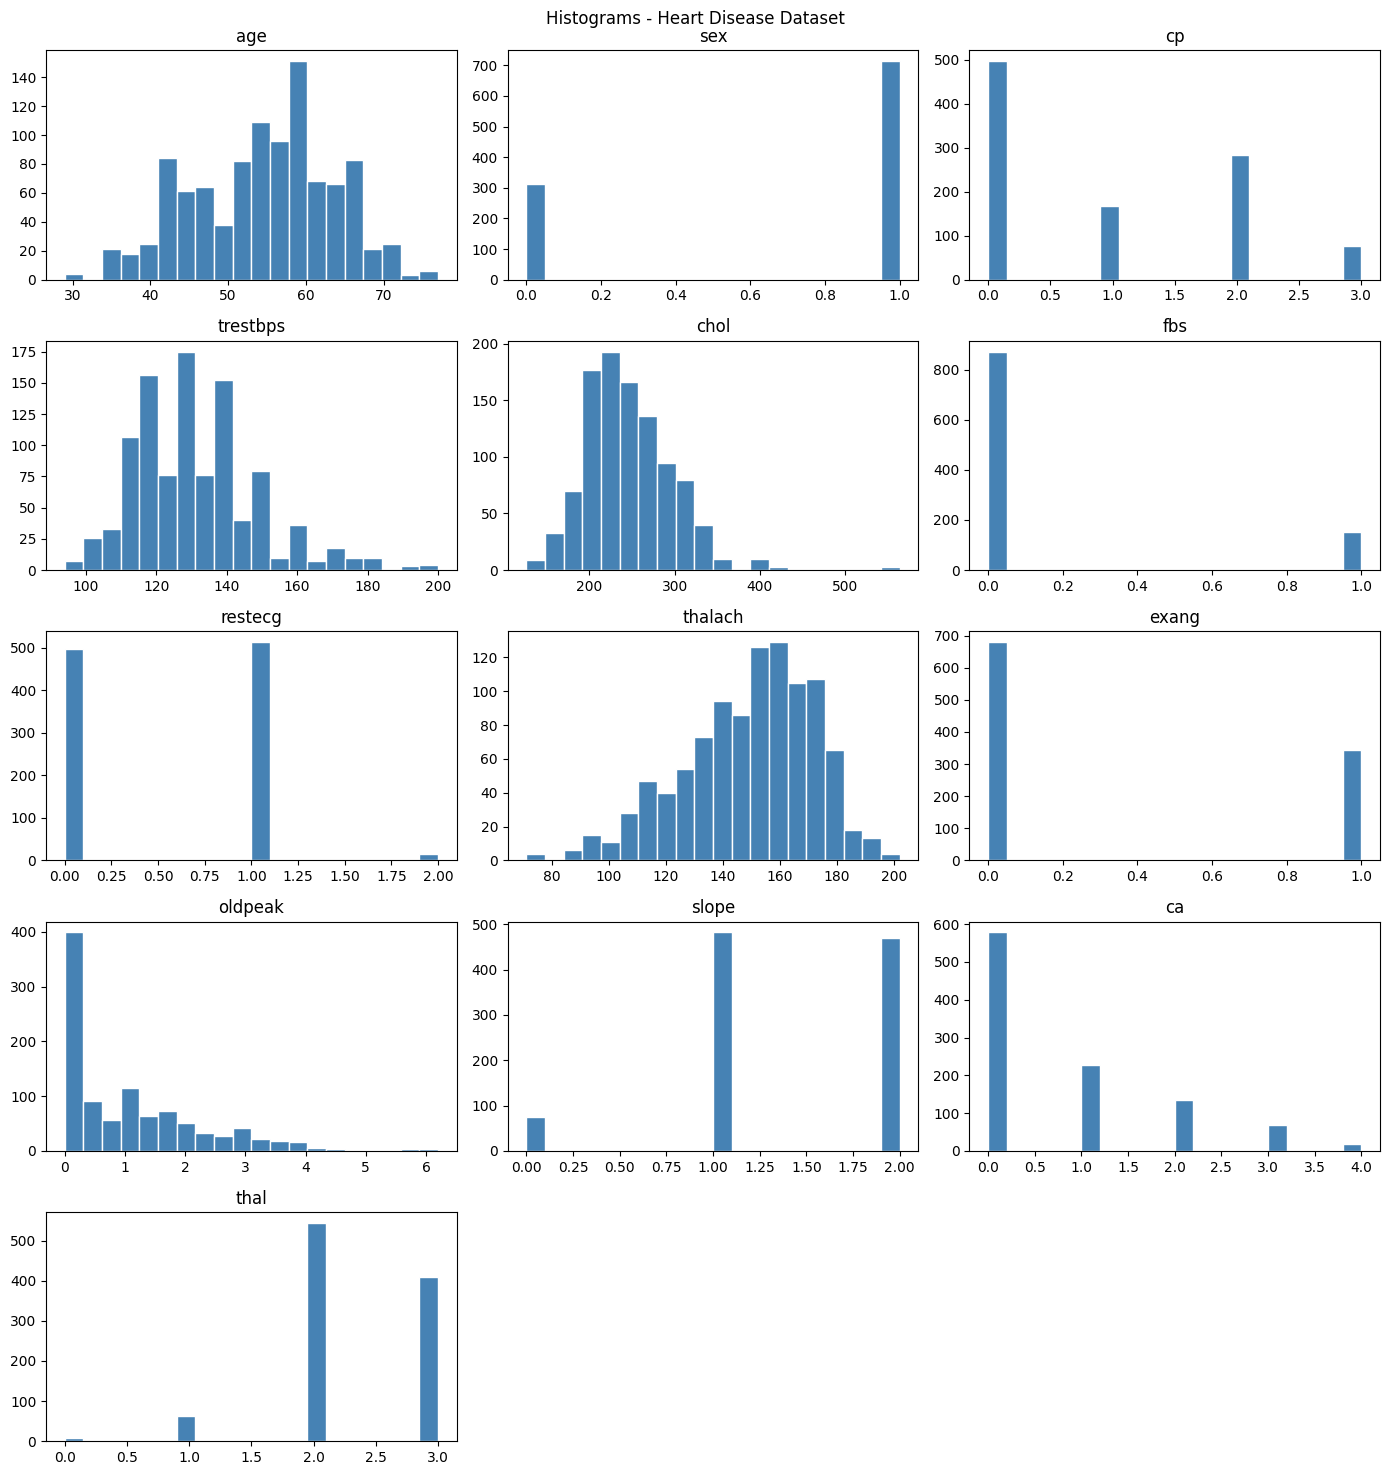

In [50]:

# ─────────────────────────────────────────────
# (ii) EDA Visualizations
# ─────────────────────────────────────────────
numeric_cols = df.drop(columns=["target"]).columns.tolist()
n = len(numeric_cols)

# Histogram
fig, axes = plt.subplots((n + 2) // 3, 3, figsize=(14, 3 * ((n + 2) // 3)))
for ax, col in zip(axes.flatten(), numeric_cols):
    ax.hist(df[col].dropna(), bins=20, color="steelblue", edgecolor="white")
    ax.set_title(col)
for ax in axes.flatten()[n:]:
    ax.set_visible(False)
plt.suptitle("Histograms - Heart Disease Dataset")
plt.tight_layout()
plt.savefig("lab22_histogram.png", dpi=100)
plt.show()


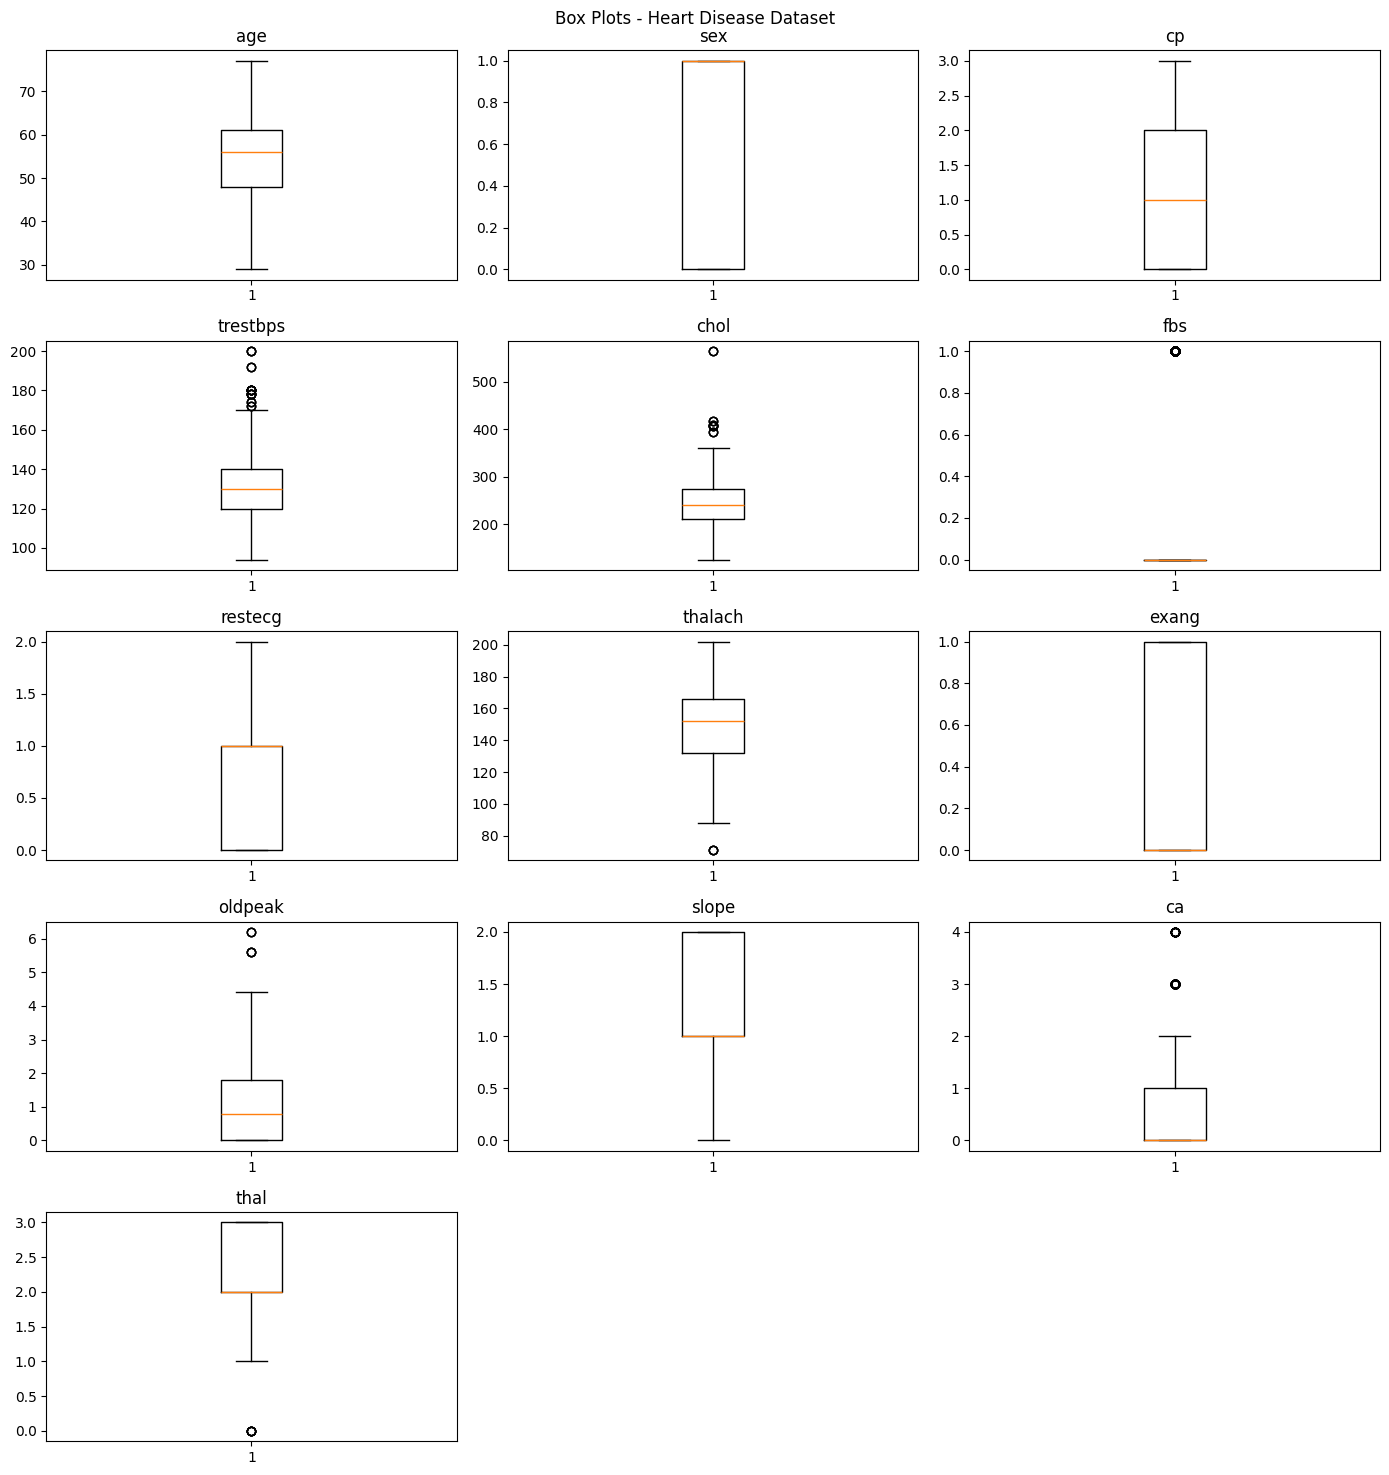

In [31]:

# Box plot
fig, axes = plt.subplots((n + 2) // 3, 3, figsize=(14, 3 * ((n + 2) // 3)))
for ax, col in zip(axes.flatten(), numeric_cols):
    ax.boxplot(df[col].dropna())
    ax.set_title(col)
for ax in axes.flatten()[n:]:
    ax.set_visible(False)
plt.suptitle("Box Plots - Heart Disease Dataset")
plt.tight_layout()
plt.savefig("lab22_boxplot.png", dpi=100)
plt.show()


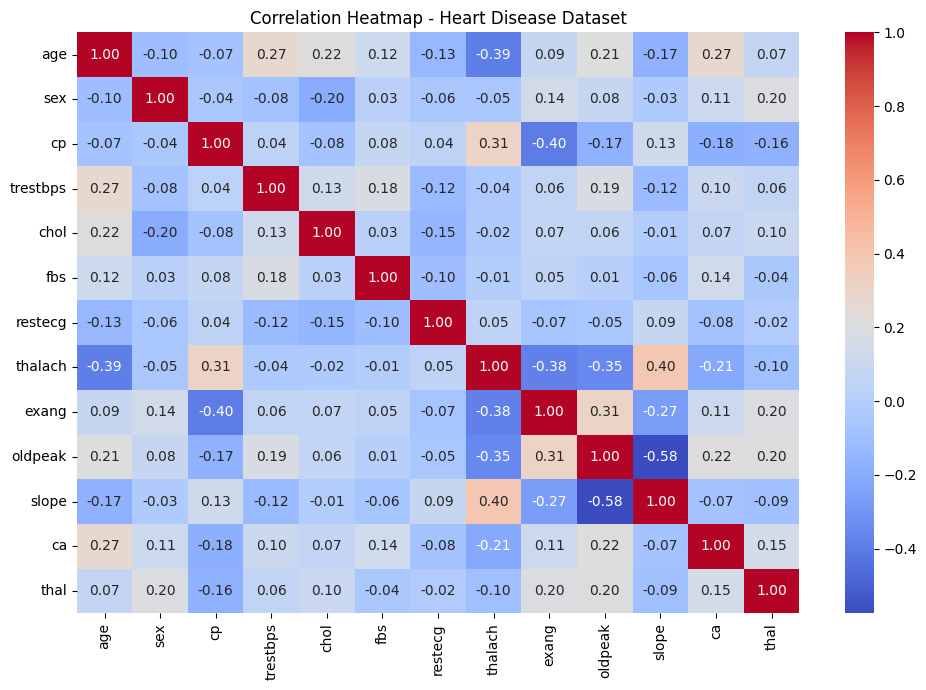

In [32]:

# Correlation heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap - Heart Disease Dataset")
plt.tight_layout()
plt.savefig("lab22_heatmap.png", dpi=100)
plt.show()


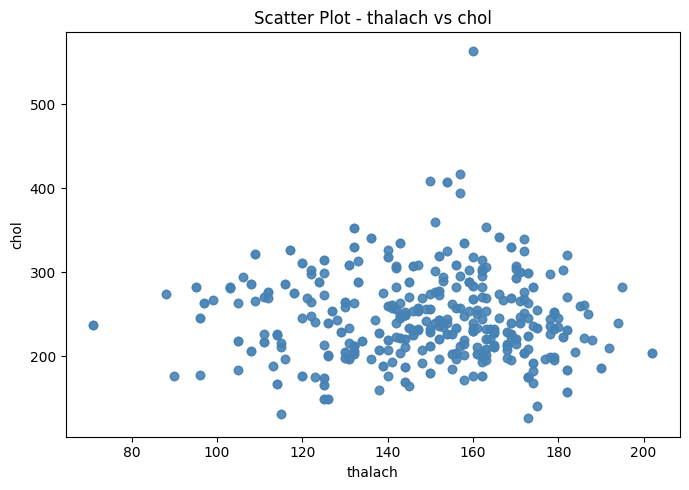

In [35]:

# Scatter plot - PLACEHOLDER: replace with two relevant columns
col1 = 'thalach'
col2 = 'chol'
plt.figure(figsize=(7, 5))
plt.scatter(df[col1], df[col2], alpha=0.5, color="steelblue")
plt.xlabel(col1)
plt.ylabel(col2)
plt.title(f"Scatter Plot - {col1} vs {col2}")
plt.tight_layout()
plt.savefig("lab22_scatter.png", dpi=100)
plt.show()


In [58]:
# ─────────────────────────────────────────────
# (iii-a) Feature encoding + scaling
# ─────────────────────────────────────────────
target = df["target"].copy()
X_raw  = df.drop(columns=["target"]).copy()

print("\nFeature columns:", X_raw.columns.tolist())



Feature columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']


In [59]:
nominal_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "thal"]
# 'ca' has 0..4 with an extra value (4) in this file, so treat it as nominal too.
nominal_cols.append("ca")

X_enc = pd.get_dummies(X_raw, columns=nominal_cols, drop_first=True)
print("Encoded shape:", X_enc.shape)

# RobustScaler: uses median / IQR, resistant to the chol=564 outlier.
scaler   = RobustScaler()
X_scaled = scaler.fit_transform(X_enc)
print("Scaled shape:", X_scaled.shape)

Encoded shape: (1025, 22)
Scaled shape: (1025, 22)


In [60]:
pca   = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Cumulative:", pca.explained_variance_ratio_.cumsum())

Explained variance ratio: [0.22809118 0.1458641 ]
Cumulative: [0.22809118 0.37395527]


In [72]:
# ─────────────────────────────────────────────
# (iii-c) K-Medoids clustering + evaluation
# ─────────────────────────────────────────────
# NOTE: sklearn_extra.cluster.KMedoids has NO n_init argument.
# Stable init: use init="k-medoids++"; optionally method="pam" for exact PAM.

results = []
print("\nk  | Silhouette | Davies-Bouldin | ARI vs target")
print("-" * 55)

for k in range(2, 6):
    km = KMedoids(
    n_clusters=k,
    metric="euclidean",
    init="k-medoids++",
    max_iter=1000,
    random_state=42,
)
    labels = km.fit_predict(X_scaled)

    sil = silhouette_score(X_scaled, labels)
    db  = davies_bouldin_score(X_scaled, labels)
    ari = adjusted_rand_score(target, labels)

    results.append({
        "k": k, "sil": sil, "db": db, "ari": ari,
        "labels": labels, "model": km,
    })
    print(f"k={k} | {sil:+.4f}    | {db:.4f}         | {ari:+.4f}")

# Choose best k by lowest Davies-Bouldin index (lower = better)
best = min(results, key=lambda r: r["db"])
best_k      = best["k"]
best_labels = best["labels"]
print(f"\nBest k = {best_k}  "
      f"(sil={best['sil']:+.4f}, DB={best['db']:.4f}, ARI={best['ari']:+.4f})")


k  | Silhouette | Davies-Bouldin | ARI vs target
-------------------------------------------------------
k=2 | +0.1401    | 2.3143         | +0.3594
k=3 | +0.1296    | 2.6445         | +0.2690
k=4 | +0.1044    | 2.6383         | +0.2091
k=5 | +0.1017    | 2.4855         | +0.1792

Best k = 2  (sil=+0.1401, DB=2.3143, ARI=+0.3594)


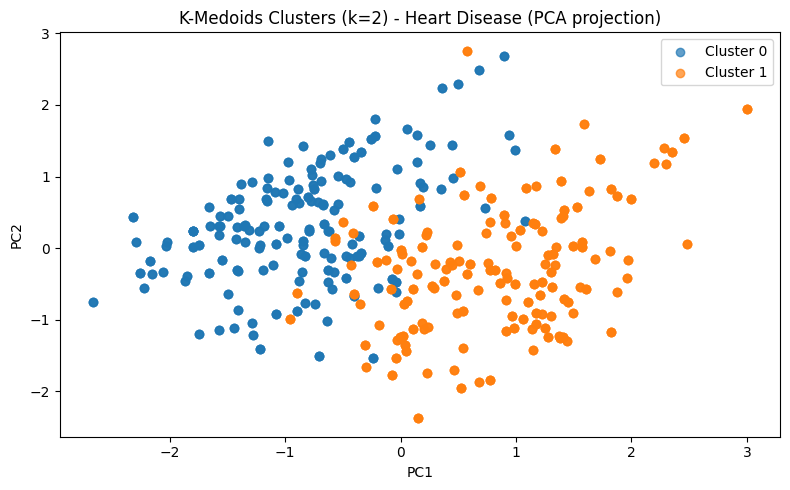

In [70]:
# ─────────────────────────────────────────────
# (iii-d) Cluster visualisation in PCA space
# ─────────────────────────────────────────────
plt.figure(figsize=(8, 5))
for c in range(best_k):
    mask = best_labels == c
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1],
                alpha=0.7, label=f"Cluster {c}")
plt.title(f"K-Medoids Clusters (k={best_k}) - Heart Disease (PCA projection)")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.legend()
plt.tight_layout()
plt.savefig(f"lab22_clusters_k{best_k}.png", dpi=100)
plt.show()


COMPARISON: k = 2  vs  k = 3   (lab requirement iii & iv)
 k    Accuracy    Silhouette   Davies-Bouldin       ARI
------------------------------------------------------------
 2      0.8000       +0.1401           2.3143   +0.3594
 3      0.6273       +0.1296           2.6445   +0.2690

VISUAL COMPARISON: k=2 vs k=3 in PCA space


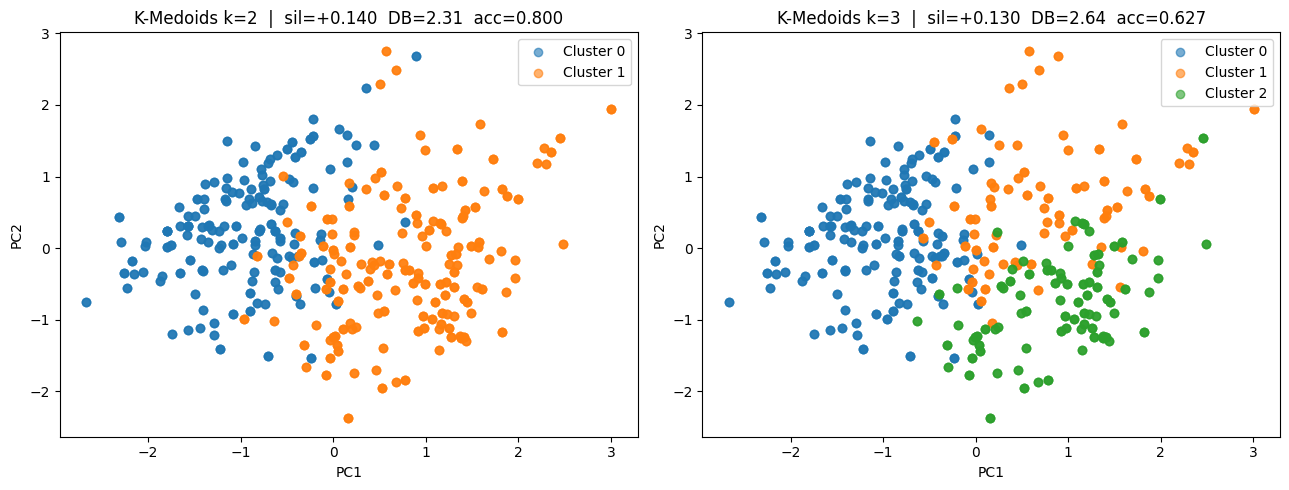

In [75]:
# ─────────────────────────────────────────────
# (iii-iv) Side-by-side comparison for k = 2 and k = 3
#          (required by the lab question: "try k=2 & k=3 and show accuracy")
# ─────────────────────────────────────────────
from scipy.optimize import linear_sum_assignment

def clustering_accuracy(y_true, y_pred):
    """Best-match accuracy: assign each cluster to the majority true class."""
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    classes = np.unique(y_true)
    clusters = np.unique(y_pred)

    # Confusion matrix (clusters × classes)
    cm = np.zeros((len(clusters), len(classes)), dtype=int)
    for i, c in enumerate(clusters):
        for j, k in enumerate(classes):
            cm[i, j] = np.sum((y_pred == c) & (y_true == k))

    # Hungarian algorithm → optimal cluster→class assignment
    row_ind, col_ind = linear_sum_assignment(-cm)
    return cm[row_ind, col_ind].sum() / len(y_true)

print("\n" + "=" * 70)
print("COMPARISON: k = 2  vs  k = 3   (lab requirement iii & iv)")
print("=" * 70)
print(f"{'k':>2}  {'Accuracy':>10}  {'Silhouette':>12}  {'Davies-Bouldin':>15}  {'ARI':>8}")
print("-" * 60)

for r in results:
    if r["k"] not in (2, 3):
        continue
    acc = clustering_accuracy(target.values, r["labels"])
    print(f"{r['k']:>2}  {acc:>10.4f}  {r['sil']:>+12.4f}  "
          f"{r['db']:>15.4f}  {r['ari']:>+8.4f}")
    # store for the report
    r["accuracy"] = acc

print("\n" + "=" * 70)
print("VISUAL COMPARISON: k=2 vs k=3 in PCA space")
print("=" * 70)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, r in zip(axes, [r for r in results if r["k"] in (2, 3)]):
    for c in range(r["k"]):
        m = r["labels"] == c
        ax.scatter(X_pca[m, 0], X_pca[m, 1], alpha=0.6, label=f"Cluster {c}")
    ax.set_title(f"K-Medoids k={r['k']}  |  sil={r['sil']:+.3f}  "
                 f"DB={r['db']:.2f}  acc={r['accuracy']:.3f}")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend()
plt.tight_layout()
plt.savefig("lab22_k2_vs_k3.png", dpi=100)
plt.show()